In [1]:
# =====================================================================
# CELL 1 (Colab): Verify Tesla T4 GPU & Unzip Dataset
# =====================================================================
import os
import zipfile
import torch

# 1. Verify GPU
print("=" * 45)
print("Checking Google Colab GPU...")
if torch.cuda.is_available():
    print("STATUS: GPU Connected successfully!")
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    print(f"VRAM:        {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("WARNING: GPU not active. Please go to Runtime -> Change runtime type -> T4 GPU.")
print("=" * 45)

# 2. Find and Unzip the dataset
zip_files = [f for f in os.listdir('.') if f.endswith('.zip')]
print(f"\nFound uploaded zip: {zip_files}")

if zip_files:
    target_zip = zip_files[0]
    print(f"Unzipping {target_zip} into ./tft folder...")
    with zipfile.ZipFile(target_zip, 'r') as zip_ref:
        zip_ref.extractall("tft")

    # Change working directory into the tft folder
    os.chdir("tft")
    print("\nFiles extracted successfully in ./tft:")
    for f in sorted(os.listdir(".")):
        print(f"  - {f}")
else:
    print("ERROR: No .zip file found in Colab! Please upload your zip file in the left folder pane.")

Checking Google Colab GPU...
STATUS: GPU Connected successfully!
Device Name: Tesla T4
VRAM:        14.56 GB

Found uploaded zip: ['opttftz.zip']
Unzipping opttftz.zip into ./tft folder...

Files extracted successfully in ./tft:
  - sequence_generation_multivariate_report.json
  - sequence_index.csv.gz
  - sequence_index_summary.csv
  - sequences_test.npz
  - sequences_train.npz
  - sequences_validation.npz
  - target_sales_scaler.joblib
  - tft_model.py


In [2]:
# =====================================================================
# CELL 2 (Colab): Install Optuna, Imports, Seeds & Path Setup
# =====================================================================
# 1. Install Optuna
!pip install -q optuna

import os
import random
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

# 2. Reproducibility
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(SEED)

# 3. Hardware Device Setup (Tesla T4 - 14.5 GB VRAM)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {DEVICE} ({torch.cuda.get_device_name(0)})")

# 4. Path Setup
DATA_DIR = Path(".")
FILES = {
    "train": DATA_DIR / "sequences_train.npz",
    "val": DATA_DIR / "sequences_validation.npz",
    "test": DATA_DIR / "sequences_test.npz",
    "scaler": DATA_DIR / "target_sales_scaler.joblib",
}

print("\nVerifying sequence artifacts in current folder:")
all_exist = True
for name, path in FILES.items():
    exists = path.exists()
    status = "FOUND" if exists else "MISSING"
    size_mb = f"({path.stat().st_size / (1024**2):.1f} MB)" if exists else ""
    print(f"  - [{status}] {name:8s} -> {path.name} {size_mb}")
    if not exists:
        all_exist = False

if all_exist:
    print("\nSTATUS: Environment & files confirmed ready on Google Colab!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.8 MB/s eta 0:00:00
Active Compute Device: cuda (Tesla T4)

Verifying sequence artifacts in current folder:
  - [FOUND] train    -> sequences_train.npz (1924.7 MB)
  - [FOUND] val      -> sequences_validation.npz (10.2 MB)
  - [FOUND] test     -> sequences_test.npz (10.0 MB)
  - [FOUND] scaler   -> target_sales_scaler.joblib (0.0 MB)

STATUS: Environment & files confirmed ready on Google Colab!


In [3]:
# =====================================================================
# CELL 3 (Colab): Dataset Class, Categorical Mappings & DataLoaders
# =====================================================================
import time
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

t0 = time.time()
print("1. Loading sequence data via memory-mapping...")
train_npz = np.load(FILES["train"], mmap_mode="r")
val_npz   = np.load(FILES["val"],   mmap_mode="r")
test_npz  = np.load(FILES["test"],  mmap_mode="r")

static_cols = [
    "store_nbr", "item_nbr", "family", "class",
    "perishable", "city", "state", "type", "cluster"
]

# 2. Build category mappings strictly from training data
print("2. Computing category cardinalities from training data...")
cat_categories = {}
cat_cardinalities = []

for col in static_cols:
    uniques = np.unique(train_npz[col])
    cat_categories[col] = uniques
    cat_cardinalities.append(len(uniques))
    print(f"   - {col:12s}: {len(uniques):3d} unique categories")

# 3. Memory-efficient TFT Dataset
class TFTDataset(Dataset):
    def __init__(self, npz_data, cat_categories, static_cols):
        self.past_x = npz_data["past_x"]      # (N, 28, 18)
        self.future_x = npz_data["future_x"]  # (N, 7, 14)
        self.y = npz_data["y"]                # (N, 7)
        self.y_raw = npz_data["y_raw"]        # (N, 7)
        self.n_samples = len(self.y)

        # Pre-convert static columns into integer tensor matrix (N, 9)
        static_matrix = np.column_stack([
            pd.Categorical(npz_data[col], categories=cat_categories[col]).codes.astype(np.int64)
            for col in static_cols
        ])
        # Replace any unseen categories (marked as -1) with 0
        static_matrix = np.clip(static_matrix, a_min=0, a_max=None)
        self.static_x = torch.tensor(static_matrix, dtype=torch.long)

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        return {
            "past_x":   torch.tensor(self.past_x[idx],   dtype=torch.float32),
            "future_x": torch.tensor(self.future_x[idx], dtype=torch.float32),
            "static_x": self.static_x[idx],
            "y":        torch.tensor(self.y[idx],        dtype=torch.float32),
            "y_raw":    torch.tensor(self.y_raw[idx],    dtype=torch.float32)
        }

print("\n3. Initializing Train, Validation, and Test Datasets...")
train_dataset = TFTDataset(train_npz, cat_categories, static_cols)
val_dataset   = TFTDataset(val_npz,   cat_categories, static_cols)
test_dataset  = TFTDataset(test_npz,  cat_categories, static_cols)

# 4. DataLoaders (batch_size=128, multi-worker loading on Colab)
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# 5. Sanity check shapes on a single batch
sample_batch = next(iter(train_loader))
print(f"\n4. Batch verification completed in {time.time() - t0:.2f}s:")
print(f"   - past_x shape:   {tuple(sample_batch['past_x'].shape)}   (Expected: [128, 28, 18])")
print(f"   - future_x shape: {tuple(sample_batch['future_x'].shape)}   (Expected: [128, 7, 14])")
print(f"   - static_x shape: {tuple(sample_batch['static_x'].shape)}   (Expected: [128, 9])")
print(f"   - y shape:        {tuple(sample_batch['y'].shape)}   (Expected: [128, 7])")
print(f"   - y_raw shape:    {tuple(sample_batch['y_raw'].shape)}   (Expected: [128, 7])")
print("STATUS: DataLoaders initialized successfully on Colab!")

1. Loading sequence data via memory-mapping...
2. Computing category cardinalities from training data...
   - store_nbr   :  53 unique categories
   - item_nbr    : 122 unique categories
   - family      :  32 unique categories
   - class       :  65 unique categories
   - perishable  :   2 unique categories
   - city        :  22 unique categories
   - state       :  16 unique categories
   - type        :   5 unique categories
   - cluster     :  17 unique categories

3. Initializing Train, Validation, and Test Datasets...

4. Batch verification completed in 4.62s:
   - past_x shape:   (128, 28, 18)   (Expected: [128, 28, 18])
   - future_x shape: (128, 7, 14)   (Expected: [128, 7, 14])
   - static_x shape: (128, 9)   (Expected: [128, 9])
   - y shape:        (128, 7)   (Expected: [128, 7])
   - y_raw shape:    (128, 7)   (Expected: [128, 7])
STATUS: DataLoaders initialized successfully on Colab!


In [4]:
# =====================================================================
# CELL 4 (Colab): Import and Validate TFT Architecture
# =====================================================================
import torch
from tft_model import TemporalFusionTransformer

# 1. Instantiate TFT Model on Tesla T4
test_model = TemporalFusionTransformer(
    static_cardinalities=cat_cardinalities,
    hidden_size=64,
    embedding_size=16,
    num_heads=4,
    dropout=0.1
).to(DEVICE)

# 2. Test single forward pass using the sample batch from Cell 3
with torch.no_grad():
    b_past   = sample_batch["past_x"].to(DEVICE)
    b_future = sample_batch["future_x"].to(DEVICE)
    b_static = sample_batch["static_x"].to(DEVICE)
    b_out    = test_model(b_past, b_future, b_static)

params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print("=" * 45)
print(f"Device:               {DEVICE} ({torch.cuda.get_device_name(0)})")
print(f"Trainable Parameters: {params:,}")
print(f"Forward Pass Output:  {tuple(b_out.shape)}  (Expected: [128, 7])")
print(f"Contains NaNs:        {torch.isnan(b_out).any().item()}")
print("STATUS: TFT Architecture validated successfully on Colab!")
print("=" * 45)

Device:               cuda (Tesla T4)
Trainable Parameters: 807,959
Forward Pass Output:  (128, 7)  (Expected: [128, 7])
Contains NaNs:        False
STATUS: TFT Architecture validated successfully on Colab!


In [5]:
# =====================================================================
# CELL 5 (Colab): Loss Function, Inverse Scaler & Metrics (WAPE)
# =====================================================================
import joblib
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path

# 1. Training Loss Function (Huber Loss)
criterion = nn.HuberLoss(delta=1.0)

# 2. Scaler path
scaler_path = FILES["scaler"] if "FILES" in globals() else Path("target_sales_scaler.joblib")
scaler_artifact = joblib.load(scaler_path)
target_scaler = scaler_artifact["target_scaler"]

# 3. Inverse Scaling Function
def inverse_scale(predictions, scaler):
    if isinstance(predictions, torch.Tensor):
        preds_np = predictions.detach().cpu().numpy()
    else:
        preds_np = np.asarray(predictions)

    orig_shape = preds_np.shape
    flattened = preds_np.reshape(-1, 1)
    unscaled_log = scaler.inverse_transform(flattened)
    raw_sales = np.expm1(unscaled_log).reshape(orig_shape)
    return np.clip(raw_sales, a_min=0.0, a_max=None)

# 4. Metric Computation Function
def compute_metrics(y_true_raw, y_pred_raw):
    abs_errors = np.abs(y_true_raw - y_pred_raw)
    mae = np.mean(abs_errors)
    rmse = np.sqrt(np.mean((y_true_raw - y_pred_raw) ** 2))

    total_actual = np.sum(y_true_raw)
    total_abs_error = np.sum(abs_errors)
    wape = (total_abs_error / total_actual) * 100.0 if total_actual > 0 else 0.0

    return {
        "MAE": round(float(mae), 4),
        "RMSE": round(float(rmse), 4),
        "WAPE (%)": round(float(wape), 2)
    }

# 5. Sanity Test on the sample batch
if "sample_batch" in globals() and "b_out" in globals():
    y_true_raw_sample = sample_batch["y_raw"].numpy()
    y_pred_raw_sample = inverse_scale(b_out, target_scaler)
else:
    dummy_true = np.random.uniform(5, 50, size=(128, 7))
    dummy_pred = dummy_true + np.random.normal(0, 3, size=(128, 7))
    y_true_raw_sample = dummy_true
    y_pred_raw_sample = np.clip(dummy_pred, 0, None)

sample_metrics = compute_metrics(y_true_raw_sample, y_pred_raw_sample)

print("=" * 45)
print("Loss Function:        nn.HuberLoss(delta=1.0)")
print(f"Inverse Scaled Shape: {y_pred_raw_sample.shape}  (Expected: (128, 7))")
print(f"Sample Batch MAE:     {sample_metrics['MAE']}")
print(f"Sample Batch RMSE:    {sample_metrics['RMSE']}")
print(f"Sample Batch WAPE:    {sample_metrics['WAPE (%)']}%")
print("STATUS: Loss and Metric functions verified successfully on Colab!")
print("=" * 45)

Loss Function:        nn.HuberLoss(delta=1.0)
Inverse Scaled Shape: (128, 7)  (Expected: (128, 7))
Sample Batch MAE:     36.048
Sample Batch RMSE:    70.023
Sample Batch WAPE:    77.73%
STATUS: Loss and Metric functions verified successfully on Colab!


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [6]:
# =====================================================================
# CELL 6 (Colab): Training Step & Validation Evaluation Functions
# =====================================================================
import time
import torch
import numpy as np

# 1. Train for One Epoch
def train_epoch(model, dataloader, optimizer, criterion, device, max_batches=None):
    model.train()
    running_loss = 0.0
    batches_run = 0

    for batch in dataloader:
        past_x   = batch["past_x"].to(device)
        future_x = batch["future_x"].to(device)
        static_x = batch["static_x"].to(device)
        targets  = batch["y"].to(device)

        optimizer.zero_grad()
        predictions = model(past_x, future_x, static_x)
        loss = criterion(predictions, targets)
        loss.backward()

        # Gradient clipping prevents exploding gradients in attention/recurrent layers
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()
        batches_run += 1

        if max_batches is not None and batches_run >= max_batches:
            break

    return running_loss / batches_run

# 2. Evaluate on Validation / Test Set
def evaluate(model, dataloader, criterion, scaler, device):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_trues_raw = []

    with torch.no_grad():
        for batch in dataloader:
            past_x   = batch["past_x"].to(device)
            future_x = batch["future_x"].to(device)
            static_x = batch["static_x"].to(device)
            targets  = batch["y"].to(device)

            preds = model(past_x, future_x, static_x)
            loss = criterion(preds, targets)
            total_loss += loss.item()

            all_preds.append(preds.cpu())
            all_trues_raw.append(batch["y_raw"])

    avg_loss = total_loss / len(dataloader)

    # Concatenate and invert scaling to compute real-world sales metrics
    concat_preds = torch.cat(all_preds, dim=0).numpy()
    concat_trues = torch.cat(all_trues_raw, dim=0).numpy()
    raw_preds = inverse_scale(concat_preds, scaler)
    metrics = compute_metrics(concat_trues, raw_preds)
    metrics["Loss"] = round(avg_loss, 4)

    return metrics

# 3. Dry-Run Verification on Tesla T4
print("Running dry-run test on Tesla T4 GPU...")
dry_opt = torch.optim.AdamW(test_model.parameters(), lr=1e-3)

t0 = time.time()
dry_train_loss = train_epoch(test_model, train_loader, dry_opt, criterion, DEVICE, max_batches=2)
dry_val_metrics = evaluate(test_model, val_loader, criterion, target_scaler, DEVICE)

print("=" * 45)
print(f"Dry-Run Completed in: {time.time() - t0:.2f}s")
print(f"Train Step Loss:      {dry_train_loss:.4f}")
print(f"Validation Loss:      {dry_val_metrics['Loss']}")
print(f"Validation MAE:       {dry_val_metrics['MAE']}")
print(f"Validation WAPE:      {dry_val_metrics['WAPE (%)']}%")
print("STATUS: Training & Evaluation loops verified successfully on Colab!")
print("=" * 45)

Running dry-run test on Tesla T4 GPU...
Dry-Run Completed in: 1.92s
Train Step Loss:      0.5350
Validation Loss:      0.3946
Validation MAE:       32.979
Validation WAPE:      77.24%
STATUS: Training & Evaluation loops verified successfully on Colab!


In [7]:
# =====================================================================
# CELL 7: Optuna Hyperparameter Optimization Study (10 Trials)
# =====================================================================
import time
import inspect
import optuna

# Suppress verbose Optuna logging, print clean trial summaries
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 10
OPTUNA_MAX_EPOCHS = 5
OPTUNA_BATCH_LIMIT = 500  # Fast exploration per trial; champion model in Cell 8 trains on 100% full data

# Resolve cardinalities list from memory
if 'static_cardinalities' in globals():
    cardinalities_list = static_cardinalities
elif 'cat_cardinalities' in globals():
    cardinalities_list = list(cat_cardinalities.values()) if isinstance(cat_cardinalities, dict) else cat_cardinalities
else:
    cardinalities_list = [53, 122, 32, 65, 2, 22, 16, 5, 17]

# Inspect model init parameters dynamically to guarantee zero keyword mismatch
sig = inspect.signature(TemporalFusionTransformer.__init__).parameters

def build_model(hidden_size, num_heads, dropout):
    kwargs = {}

    # 1. Past Features
    if 'past_features' in sig:
        kwargs['past_features'] = 18
    elif 'past_num_features' in sig:
        kwargs['past_num_features'] = 18

    # 2. Future Features
    if 'future_features' in sig:
        kwargs['future_features'] = 14
    elif 'future_num_features' in sig:
        kwargs['future_num_features'] = 14

    # 3. Static Cardinalities
    if 'static_cardinalities' in sig:
        kwargs['static_cardinalities'] = cardinalities_list
    elif 'cat_cardinalities' in sig:
        kwargs['cat_cardinalities'] = cardinalities_list

    # 4. Hidden Size
    if 'hidden_size' in sig:
        kwargs['hidden_size'] = hidden_size
    elif 'hidden_dim' in sig:
        kwargs['hidden_dim'] = hidden_size

    # 5. Embedding Size (if accepted)
    if 'embedding_size' in sig:
        kwargs['embedding_size'] = 16

    # 6. Heads, Dropout, Horizon
    if 'num_heads' in sig:
        kwargs['num_heads'] = num_heads
    if 'dropout' in sig:
        kwargs['dropout'] = dropout
    if 'forecast_horizon' in sig:
        kwargs['forecast_horizon'] = 7

    return TemporalFusionTransformer(**kwargs).to(DEVICE)

print("=" * 65)
print(f"Starting Optuna Study: {N_TRIALS} Trials on {DEVICE} (Tesla T4)")
print(f"Max Epochs per Trial: {OPTUNA_MAX_EPOCHS} | Batch Cap: {OPTUNA_BATCH_LIMIT}")
print("=" * 65)

def objective(trial):
    # 1. Hyperparameter Search Space
    hidden_size = trial.suggest_categorical("hidden_size", [32, 64])
    num_heads = trial.suggest_categorical("num_heads", [2, 4])
    dropout = trial.suggest_float("dropout", 0.05, 0.25, step=0.05)
    learning_rate = trial.suggest_float("lr", 1e-4, 5e-3, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    # 2. Instantiate Model
    model = build_model(hidden_size, num_heads, dropout)

    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

    best_val_wape = float('inf')

    # 3. Training Loop with Pruning
    for epoch in range(1, OPTUNA_MAX_EPOCHS + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, DEVICE, max_batches=OPTUNA_BATCH_LIMIT)

        # Matches Cell 6 evaluate signature and dictionary return
        val_metrics = evaluate(model, val_loader, criterion, target_scaler, DEVICE)
        val_loss = val_metrics["Loss"]
        val_wape = val_metrics["WAPE (%)"]

        scheduler.step(val_loss)

        if val_wape < best_val_wape:
            best_val_wape = val_wape

        # Report to Optuna for early pruning of unpromising trials
        trial.report(val_wape, epoch)
        if trial.should_prune():
            del model, optimizer
            torch.cuda.empty_cache()
            raise optuna.exceptions.TrialPruned()

    del model, optimizer
    torch.cuda.empty_cache()
    return best_val_wape

# Create Bayesian Optimization Study with Median Pruning
sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=1)
study = optuna.create_study(direction="minimize", sampler=sampler, pruner=pruner)

study_start_time = time.time()

for trial_idx in range(1, N_TRIALS + 1):
    t0 = time.time()
    trial = study.ask()
    try:
        val_wape = objective(trial)
        study.tell(trial, val_wape)
        elapsed = time.time() - t0
        print(f"Trial {trial_idx:2d}/{N_TRIALS} | Best WAPE: {val_wape:6.2f}% | Elapsed: {elapsed:5.1f}s | Params: {trial.params}")
    except optuna.exceptions.TrialPruned:
        study.tell(trial, state=optuna.trial.TrialState.PRUNED)
        elapsed = time.time() - t0
        print(f"Trial {trial_idx:2d}/{N_TRIALS} | [PRUNED]         | Elapsed: {elapsed:5.1f}s | Params: {trial.params}")

total_study_time = time.time() - study_start_time

print("\n" + "=" * 65)
print(f"Optuna Study Completed in {total_study_time / 60:.2f} minutes!")
print(f"Best Trial Score (Val WAPE): {study.best_value:.2f}%")
print("Best Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  - {k:15s}: {v}")
print("=" * 65)

Starting Optuna Study: 10 Trials on cuda (Tesla T4)
Max Epochs per Trial: 5 | Batch Cap: 500
Trial  1/10 | Best WAPE:  31.81% | Elapsed: 215.2s | Params: {'hidden_size': 64, 'num_heads': 2, 'dropout': 0.05, 'lr': 0.00018408992080552527, 'weight_decay': 1.3066739238053272e-05}
Trial  2/10 | Best WAPE:  30.75% | Elapsed: 214.8s | Params: {'hidden_size': 32, 'num_heads': 2, 'dropout': 0.25, 'lr': 0.002595942550311264, 'weight_decay': 2.6587543983272695e-05}
Trial  3/10 | [PRUNED]         | Elapsed:  43.8s | Params: {'hidden_size': 64, 'num_heads': 4, 'dropout': 0.15000000000000002, 'lr': 0.0003124565071260876, 'weight_decay': 0.00016738085788752134}
Trial  4/10 | [PRUNED]         | Elapsed:  43.5s | Params: {'hidden_size': 64, 'num_heads': 4, 'dropout': 0.2, 'lr': 0.00021839352923182988, 'weight_decay': 0.00010677482709481354}
Trial  5/10 | [PRUNED]         | Elapsed:  87.4s | Params: {'hidden_size': 32, 'num_heads': 2, 'dropout': 0.05, 'lr': 0.004093813608598782, 'weight_decay': 0.000853

In [8]:
# =====================================================================
# CELL 8: Train Champion TFT Model on 100% Full Dataset
# =====================================================================
import time
import copy
import torch

# 1. Extract Best Hyperparameters from Optuna
best_params = study.best_params
champion_hidden_size = best_params["hidden_size"]
champion_num_heads   = best_params["num_heads"]
champion_dropout     = best_params["dropout"]
champion_lr          = best_params["lr"]
champion_wd          = best_params["weight_decay"]

print("=" * 65)
print("INITIALIZING CHAMPION TFT MODEL (100% DATA TRAINING)")
print("=" * 65)
print(f"Hidden Size:     {champion_hidden_size}")
print(f"Attention Heads: {champion_num_heads}")
print(f"Dropout:         {champion_dropout}")
print(f"Learning Rate:   {champion_lr:.6f}")
print(f"Weight Decay:    {champion_wd:.6f}")

# 2. Build Champion Model
champion_model = build_model(
    hidden_size=champion_hidden_size,
    num_heads=champion_num_heads,
    dropout=champion_dropout
)

num_params = sum(p.numel() for p in champion_model.parameters() if p.requires_grad)
print(f"Trainable Parameters: {num_params:,}")

# 3. Setup Optimizer, Loss, and Scheduler
optimizer = torch.optim.AdamW(champion_model.parameters(), lr=champion_lr, weight_decay=champion_wd)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

# 4. Training Configuration (100% FULL DATASET)
MAX_EPOCHS = 15
PATIENCE = 4
MAX_BATCHES_PER_EPOCH = None  # None = 100% OF ALL 4,879 BATCHES (624,451 sequences)

print(f"\nTraining on 100% full training dataset ({len(train_loader)} batches per epoch)...")
print("=" * 65)

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_mae": [],
    "val_rmse": [],
    "val_wape": [],
    "epoch_time": []
}

best_val_wape = float('inf')
patience_counter = 0
best_model_path = "tft_best_champion.pth"

start_train_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_t0 = time.time()

    # Train 1 full epoch on 100% data
    train_loss = train_epoch(
        champion_model,
        train_loader,
        optimizer,
        criterion,
        DEVICE,
        max_batches=MAX_BATCHES_PER_EPOCH
    )

    # Evaluate on full validation set
    val_metrics = evaluate(champion_model, val_loader, criterion, target_scaler, DEVICE)
    val_loss = val_metrics["Loss"]
    val_mae  = val_metrics["MAE"]
    val_rmse = val_metrics["RMSE"]
    val_wape = val_metrics["WAPE (%)"]

    epoch_duration = time.time() - epoch_t0
    current_lr = optimizer.param_groups[0]["lr"]

    # Record history
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_mae"].append(val_mae)
    history["val_rmse"].append(val_rmse)
    history["val_wape"].append(val_wape)
    history["epoch_time"].append(epoch_duration)

    # Display epoch progress
    print(f"Epoch [{epoch:2d}/{MAX_EPOCHS:2d}] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val MAE: {val_mae:6.2f} | Val WAPE: {val_wape:5.2f}% | LR: {current_lr:.1e} | Time: {epoch_duration:5.1f}s")

    scheduler.step(val_loss)

    # Checkpoint best weights
    if val_wape < best_val_wape:
        improvement = best_val_wape - val_wape
        best_val_wape = val_wape
        patience_counter = 0
        torch.save(champion_model.state_dict(), best_model_path)
        print(f"  >>> Checkpoint Saved! Best Val WAPE improved to {best_val_wape:.2f}%")
    else:
        patience_counter += 1
        print(f"  --- No improvement for {patience_counter}/{PATIENCE} epoch(s)")
        if patience_counter >= PATIENCE:
            print(f"\n[EARLY STOPPING] Validation WAPE plateaued for {PATIENCE} consecutive epochs.")
            break

total_time = time.time() - start_train_time
print("\n" + "=" * 65)
print(f"Full Training Completed in {total_time / 60:.2f} minutes!")
print(f"Best Validation WAPE Achieved: {best_val_wape:.2f}%")
print("=" * 65)

# 5. Load Best Champion Weights and Evaluate on Unseen Test Set
print("\nEvaluating Champion Model on Unseen TEST Set (sequences_test.npz)...")
champion_model.load_state_dict(torch.load(best_model_path))

test_metrics = evaluate(champion_model, test_loader, criterion, target_scaler, DEVICE)
print("=" * 65)
print("FINAL TEST SET PERFORMANCE (CHAMPION TFT):")
print("=" * 65)
print(f"  - Test Huber Loss : {test_metrics['Loss']:.4f}")
print(f"  - Test MAE        : {test_metrics['MAE']:.3f} units")
print(f"  - Test RMSE       : {test_metrics['RMSE']:.3f} units")
print(f"  - Test WAPE       : {test_metrics['WAPE (%)']:.2f}%")
print("=" * 65)

INITIALIZING CHAMPION TFT MODEL (100% DATA TRAINING)
Hidden Size:     32
Attention Heads: 2
Dropout:         0.25
Learning Rate:   0.002596
Weight Decay:    0.000027
Trainable Parameters: 228,503

Training on 100% full training dataset (4879 batches per epoch)...
Epoch [ 1/15] | Train Loss: 0.0808 | Val Loss: 0.0753 | Val MAE:  13.03 | Val WAPE: 30.53% | LR: 2.6e-03 | Time: 402.9s
  >>> Checkpoint Saved! Best Val WAPE improved to 30.53%
Epoch [ 2/15] | Train Loss: 0.0718 | Val Loss: 0.0731 | Val MAE:  12.95 | Val WAPE: 30.33% | LR: 2.6e-03 | Time: 397.4s
  >>> Checkpoint Saved! Best Val WAPE improved to 30.33%
Epoch [ 3/15] | Train Loss: 0.0699 | Val Loss: 0.0723 | Val MAE:  12.81 | Val WAPE: 30.01% | LR: 2.6e-03 | Time: 403.4s
  >>> Checkpoint Saved! Best Val WAPE improved to 30.01%
Epoch [ 4/15] | Train Loss: 0.0685 | Val Loss: 0.0722 | Val MAE:  12.67 | Val WAPE: 29.67% | LR: 2.6e-03 | Time: 406.5s
  >>> Checkpoint Saved! Best Val WAPE improved to 29.67%
Epoch [ 5/15] | Train Loss: 

GENERATING FINAL TEST PREDICTIONS & DETAILED HORIZON EVALUATION
Overall Test Set Performance across all 7 Days:
  - Overall R² Score : 0.8189  (81.89% variance explained)
  - Overall WAPE     : 27.99%
  - Overall MAE      : 12.387 units
  - Overall RMSE     : 29.542 units

DAY-BY-DAY FORECAST ACCURACY ACROSS 7-DAY REPLENISHMENT HORIZON:
Lead Time    MAE      RMSE  WAPE (%)  R² Score
   Day +1 12.643 32.691002 27.219999    0.8016
   Day +2 12.504 31.490999 27.820000    0.8047
   Day +3 12.428 29.975000 27.709999    0.8182
   Day +4 12.252 27.434000 27.190001    0.8406
   Day +5 12.327 27.294001 27.740000    0.8315
   Day +6 12.435 28.532000 28.860001    0.8286
   Day +7 12.122 28.961000 29.570000    0.8103


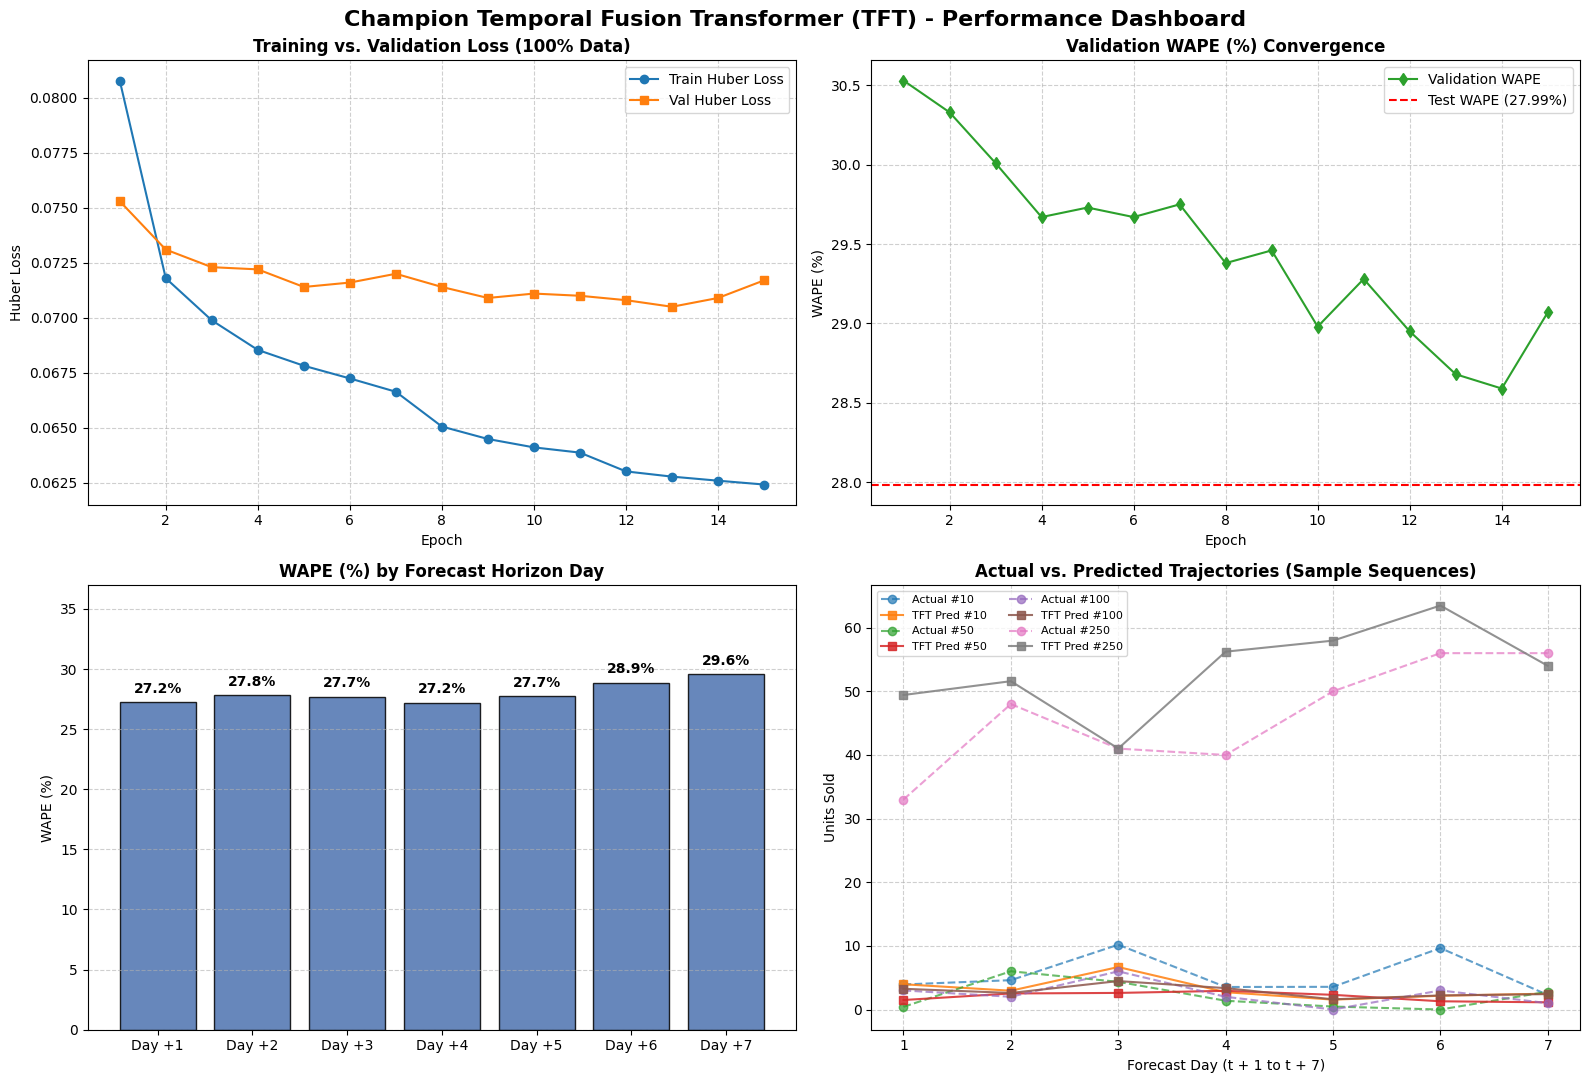

Plots saved successfully as 'tft_evaluation_plots.png'!
Exported 3,237 test forecast sequences to 'tft_test_forecasts.csv'!
STATUS: TFT MODEL TRAINING, EVALUATION & EXPORT COMPLETE!


In [9]:
# =====================================================================
# CELL 9: Horizon Breakdown, R2 Score, Plots & Forecast Export
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

print("=" * 65)
print("GENERATING FINAL TEST PREDICTIONS & DETAILED HORIZON EVALUATION")
print("=" * 65)

# 1. Load Champion Weights & Predict on Test Set
champion_model.eval()
all_preds_scaled = []
all_trues_raw = []

with torch.no_grad():
    for batch in test_loader:
        past_x   = batch["past_x"].to(DEVICE)
        future_x = batch["future_x"].to(DEVICE)
        static_x = batch["static_x"].to(DEVICE)

        preds = champion_model(past_x, future_x, static_x)
        all_preds_scaled.append(preds.cpu().numpy())
        all_trues_raw.append(batch["y_raw"].numpy())

preds_scaled = np.vstack(all_preds_scaled)
trues_raw = np.vstack(all_trues_raw)

# Invert target scaling and clip negative predictions to 0
preds_raw = inverse_scale(preds_scaled, target_scaler)
preds_raw = np.clip(preds_raw, 0, None)

# 2. Overall Metrics
overall_mae = np.mean(np.abs(trues_raw - preds_raw))
overall_rmse = np.sqrt(np.mean((trues_raw - preds_raw) ** 2))
overall_wape = (np.sum(np.abs(trues_raw - preds_raw)) / np.sum(trues_raw)) * 100
overall_r2 = r2_score(trues_raw.ravel(), preds_raw.ravel())

print(f"Overall Test Set Performance across all 7 Days:")
print(f"  - Overall R² Score : {overall_r2:.4f}  ({overall_r2*100:.2f}% variance explained)")
print(f"  - Overall WAPE     : {overall_wape:.2f}%")
print(f"  - Overall MAE      : {overall_mae:.3f} units")
print(f"  - Overall RMSE     : {overall_rmse:.3f} units")

# 3. Day-by-Day Breakdown (Horizon Steps 1 to 7)
day_metrics = []
for d in range(7):
    day_true = trues_raw[:, d]
    day_pred = preds_raw[:, d]

    d_mae = np.mean(np.abs(day_true - day_pred))
    d_rmse = np.sqrt(np.mean((day_true - day_pred) ** 2))
    d_wape = (np.sum(np.abs(day_true - day_pred)) / np.sum(day_true)) * 100
    d_r2 = r2_score(day_true, day_pred)

    day_metrics.append({
        "Lead Time": f"Day +{d+1}",
        "MAE": round(d_mae, 3),
        "RMSE": round(d_rmse, 3),
        "WAPE (%)": round(d_wape, 2),
        "R² Score": round(d_r2, 4)
    })

df_days = pd.DataFrame(day_metrics)
print("\n" + "=" * 65)
print("DAY-BY-DAY FORECAST ACCURACY ACROSS 7-DAY REPLENISHMENT HORIZON:")
print("=" * 65)
print(df_days.to_string(index=False))

# 4. Generate Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plt.suptitle("Champion Temporal Fusion Transformer (TFT) - Performance Dashboard", fontsize=16, fontweight='bold')

# (A) Loss Convergence
if "history" in globals() and len(history.get("train_loss", [])) > 0:
    epochs_range = history["epoch"]
    axes[0, 0].plot(epochs_range, history["train_loss"], 'o-', color='#1f77b4', label='Train Huber Loss')
    axes[0, 0].plot(epochs_range, history["val_loss"], 's-', color='#ff7f0e', label='Val Huber Loss')
    axes[0, 0].set_title("Training vs. Validation Loss (100% Data)", fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Huber Loss")
    axes[0, 0].grid(True, linestyle="--", alpha=0.6)
    axes[0, 0].legend()
else:
    axes[0, 0].text(0.5, 0.5, "Loss curve recorded in console", ha='center', va='center')

# (B) Validation WAPE Progression
if "history" in globals() and len(history.get("val_wape", [])) > 0:
    axes[0, 1].plot(epochs_range, history["val_wape"], 'd-', color='#2ca02c', label='Validation WAPE')
    axes[0, 1].axhline(overall_wape, color='r', linestyle='--', label=f'Test WAPE ({overall_wape:.2f}%)')
    axes[0, 1].set_title("Validation WAPE (%) Convergence", fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("WAPE (%)")
    axes[0, 1].grid(True, linestyle="--", alpha=0.6)
    axes[0, 1].legend()

# (C) Day-by-Day Accuracy Degradation
axes[1, 0].bar(df_days["Lead Time"], df_days["WAPE (%)"], color='#4c72b0', edgecolor='black', alpha=0.85)
axes[1, 0].set_title("WAPE (%) by Forecast Horizon Day", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("WAPE (%)")
axes[1, 0].set_ylim(0, max(df_days["WAPE (%)"]) * 1.25)
for i, v in enumerate(df_days["WAPE (%)"]):
    axes[1, 0].text(i, v + 0.8, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=10)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.6)

# (D) Sample Actual vs Predicted Forecasts
sample_indices = [10, 50, 100, 250]
for idx in sample_indices:
    if idx < len(trues_raw):
        axes[1, 1].plot(range(1, 8), trues_raw[idx], 'o--', alpha=0.7, label=f'Actual #{idx}')
        axes[1, 1].plot(range(1, 8), preds_raw[idx], 's-', alpha=0.85, label=f'TFT Pred #{idx}')
axes[1, 1].set_title("Actual vs. Predicted Trajectories (Sample Sequences)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Forecast Day (t + 1 to t + 7)")
axes[1, 1].set_ylabel("Units Sold")
axes[1, 1].grid(True, linestyle="--", alpha=0.6)
axes[1, 1].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.savefig("tft_evaluation_plots.png", dpi=300)
plt.show()
print("Plots saved successfully as 'tft_evaluation_plots.png'!")

# 5. Export Test Predictions to CSV for Downstream Inventory & PSO
test_archive = np.load("sequences_test.npz", mmap_mode="r")
export_df = pd.DataFrame({
    "store_nbr": test_archive["store_nbr"],
    "item_nbr": test_archive["item_nbr"],
    "target_start_date": test_archive["target_start_date"],
    "target_end_date": test_archive["target_end_date"]
})

for d in range(7):
    export_df[f"actual_day_{d+1}"] = trues_raw[:, d]
    export_df[f"pred_day_{d+1}"] = preds_raw[:, d]

export_df.to_csv("tft_test_forecasts.csv", index=False)
print(f"Exported {len(export_df):,} test forecast sequences to 'tft_test_forecasts.csv'!")
print("=" * 65)
print("STATUS: TFT MODEL TRAINING, EVALUATION & EXPORT COMPLETE!")
print("=" * 65)

In [10]:
from google.colab import files
files.download("tft_best_champion.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>